# Web Scraping Water Level Data

This notebook provides a complete pipeline for scraping historical water level data from the **Hydrological and Water Quality Database (MLIT Japan)**.

### Core Dependencies
- **Selenium**: Used for automated browser interaction (navigating pages, switching iframes).
- **BeautifulSoup**: Used for parsing the HTML content retrieved by Selenium.
- **Pandas**: Used for data manipulation, cleaning, and time-series visualization.

In [12]:
from bs4 import BeautifulSoup
from selenium import webdriver
from selenium.webdriver.common.by import By
import pandas as pd

## 1. Automated Scraper (`scrapeWaterLevel`)

The `scrapeWaterLevel` function is the main entry point. It automates the following workflow:

1.  **Date Chunking**: Splits a long request (e.g., 30 years) into manageable chunks (default 20 days per request) to avoid database timeouts or server errors.
2.  **Looping**: Iterates through each date range, constructs the specific URL for that interval, and calls the scraper.
3.  **Aggregation**: Collects all scraped rows across all intervals and converts them into a single, clean Pandas DataFrame.

**Parameters:**
- `station_id`: Unique identifier for the river observation station (e.g., `303051283310020`).
- `start_date` / `end_date`: The acquisition period in `YYYY/mm/dd` format.

In [13]:
def scrapeWaterLevel(station_id, start_date, end_date, time_interval=20):
    """
    Scrape water level data for a specified station and period from the Hydrological and Water Quality Database.
    Database URL: http://www1.river.go.jp/
    
    Args:
        station_id (int): ID of the observation station
        start_date: Start date for acquisition (format: YYYY/mm/dd)
        end_date: End date for acquisition (format: YYYY/mm/dd)
    Returns:
        df_wl (pandas.DataFrame): DataFrame containing the scraped data
    """
    # Declare the base URL (placeholders for ID, start date, and end date)
    url = 'http://www1.river.go.jp/cgi-bin/DspWaterData.exe?KIND=1&ID={0}&BGNDATE={1}&ENDDATE={2}&KAWABOU=NO'
    
    # Generate the list of dates
    date_list = fetchDateList(start_date, end_date, time_interval=20)
    
    # Loop through the date intervals
    wl_data_list = []
    for date in date_list:
        begin, end = date[0], date[1]
        url_tmp = url.format(station_id, begin, end)
        wl_data = subtractWlData(url_tmp)
        
        # If no data is found, skip to the next loop
        if wl_data is None:
            continue
        wl_data_list += wl_data
        
    # Convert the list to a DataFrame
    df_wl = list2dataframe(wl_data_list)
    return df_wl

In [14]:
import datetime

def fetchDateList(start_date, end_date, time_interval=20):
    """
    Generate an array of start and end times to retrieve data from the Hydrological and Water Quality Database.
    The array is generated based on the specified time_interval (in days).
    
    Args:
        start_date: Start date for acquisition (format: YYYY/mm/dd)
        end_date: End date for acquisition (format: YYYY/mm/dd)
    Returns:
        date_list (list): List of date ranges for acquisition
    """
    # Convert string-formatted date to datetime objects
    start_datetime = datetime.datetime.strptime(start_date, "%Y/%m/%d")
    end_datetime = datetime.datetime.strptime(end_date, "%Y/%m/%d")
    
    end_flag = False
    proceeded_date = 0
    date_list = []
    
    while(not end_flag):
        # Generate start and end times for data retrieval
        search_bgn_datetime = start_datetime + datetime.timedelta(days=proceeded_date)
        search_end_datetime = start_datetime + datetime.timedelta(days=proceeded_date + time_interval -1)
        
        # If search_end_datetime exceeds end_date, set end_flag to True to stop the loop
        if search_end_datetime >= end_datetime:
            search_end_datetime = end_datetime
            end_flag = True
        proceeded_date += time_interval
        date_list.append([search_bgn_datetime.strftime("%Y%m%d"), search_end_datetime.strftime("%Y%m%d")])
    
    return date_list

## 2. Scraping Logic (`subtractWlData`)

This function handles the technical interaction with the database website via Selenium:

- **Browser Control**: It initializes a **Headless Chrome** instance (running in the background).
- **Navigation**: It navigates directly to the results page generated by the MLIT database.
- **Iframe Handling**: Crucial Step. Since the database displays information inside an internal frame (`<iframe>`), Selenium must "switch" its focus to retrieve the actual table data.
- **Parsing**: BeautifulSoup is used to find the data table and extract all rows (`<tr>`) and cells (`<td>`). It handles the removal of the specific Japanese space character (`\u3000`) to ensure clean text.

In [15]:
def subtractWlData(url):
    """
    Extract water level data from the specified URL and return as a list.
    
    Args:
        url (String): Target URL for data acquisition
    Returns:
        wl_data_list (list): Array of water level data
    """
    try: 
        # Initialize the driver and navigate to the specified page
        driver = createDriver()
        driver.get(url)
        
        # Locate the iframe to access the water level data
        iframe = driver.find_element(By.TAG_NAME, 'iframe')
        driver.switch_to.frame(iframe)
        
        # Get the iframe source and extract all 'tr' tags from the table
        soup = BeautifulSoup(driver.page_source, 'html.parser')
        table = soup.find_all("table")[0]
        rows = table.find_all("tr")
        driver.close()
    except Exception as e:
        print(f"Error scraping {url}: {e}")
        return None
    
    # Generate the water level data list from the table rows
    wl_data_list = []
    for row in rows:
        list_tmp = []
        td_list = row.find_all(['td'])
        for td in td_list:
            list_tmp.append(td.get_text().replace('\u3000', ''))
        wl_data_list.append(list_tmp)
    
    return wl_data_list

## 3. Local Driver Setup (`createDriver`)

In the updated version of this code:
- We use a **local Chrome Driver** instead of a remote server. 
- This ensures the script works directly in your environment without needing a separate Selenium hub on port 4444.
- The `--headless` option is used so the scraping happens without opening a visible browser window.

In [16]:
def createDriver():
    """
    Initialize the Selenium driver for browser operations.
    
    Args:
        None
    Returns:
        driver (selenium.webdriver.chrome.webdriver.WebDriver): 
            Selenium Chrome driver for browser control
    """
    # Configure Chrome options
    options = webdriver.ChromeOptions()
    options.add_argument('--headless')

    # Initialize a local Chrome driver
    driver = webdriver.Chrome(options=options)
    
    return driver

## 4. Data Formatting (`list2dataframe`)

Once the raw text list is extracted, this function transforms it into a machine-readable time series:

- **Timestamp Merging**: Combines the 'Date' and 'Time' columns into a single string.
- **Midnight Correction**: Standard Python libraries cannot parse `24:00`. We use the `str2datetime` helper to convert any record at `24:00` into `00:00` of the next calendar day.
- **Type Conversion**: Converts water level strings to numeric floats. Any missing data points are converted to `NaN`.
- **Indexing**: Sets the cleaned `date` column as the DataFrame index and sorts it chronologically to enable easy plotting.

In [17]:
def list2dataframe(wl_list):
    """
    Convert the list of raw data retrieved via scraping into a DataFrame.
    
    Args:
        wl_list (list): List of water level data. Assumed format: [date, time, water level].
    Returns:
        df_wl (pandas.DataFrame): The resulting water level DataFrame
    """
    # Convert list to Pandas DataFrame and merge date and time columns
    df_wl = pd.DataFrame(wl_list, columns=['date', 'time', 'water_lev'])
    df_wl.loc[:, 'date'] = df_wl.loc[:, 'date'] + ' ' + df_wl.loc[:, 'time']
    df_wl.drop('time', axis=1, inplace=True)
    df_wl.dropna(how='all', inplace=True)
    
    # Convert 'date' to datetime format and 'water_lev' (water level) to float
    df_wl['date'] = df_wl['date'].astype('str').apply(str2datetime)
    df_wl['water_lev'] = pd.to_numeric(df_wl['water_lev'], errors='coerce')
    df_wl.set_index('date', inplace=True)
    df_wl.sort_index(inplace=True)
    
    return df_wl

In [18]:
def str2datetime(string):
    """
    Convert a date string to a datetime object.
    Translates 'YYYY/MM/DD 24:00' to the equivalent 'YYYY/MM/DD+1 00:00'.
    
    Args:
        string (String): Date string in 'YYYY/MM/DD HH:mm' format.
    Returns:
        date (datetime.datetime): Resulting datetime object
    """
    if string[-5:] == '24:00':
        string = string[:-5] + ' ' + '00:00'
        date = datetime.datetime.strptime(string, "%Y/%m/%d %H:%M")
        date += datetime.timedelta(days=1)
    else:
        date = datetime.datetime.strptime(string, "%Y/%m/%d %H:%M")
    return date

In [19]:
# Data Acquisition
start_date_test = '1990/01/01'
end_date_test = '2020/01/01'
station_id = 303051283310020

wl_data_list_test = scrapeWaterLevel(station_id, start_date_test, end_date_test)

## 5. Result Visualization

The final cells demonstrate the usage:
- **`scrapeWaterLevel`**: Fetches data from 1990 to 2020.
- **`plot()`**: Generates a Matplotlib line graph showing the fluctuations in water level over three decades.
- **`info()`**: Provides a summary of the dataset, confirming the total number of entries and that the data types are correct for further analysis.

<Axes: xlabel='date'>

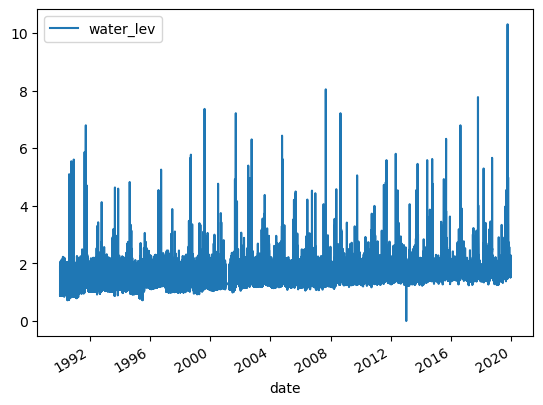

In [20]:
wl_data_list_test.plot()

In [21]:
wl_data_list_test.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 260832 entries, 1990-01-01 01:00:00 to 2020-01-02 00:00:00
Data columns (total 1 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   water_lev  260186 non-null  float64
dtypes: float64(1)
memory usage: 4.0 MB
